## **Exercise: Model Complexity in Linear Model**


**Gunakan dataset 'Admission_Predict'**

        - Features: 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA'
        - Target: 'Chance of Admit'

- Lakukan data splitting dengan proporsi 80:20 dan random_state = 42.

- Gunakan model Ridge Regression dan Lasso Regression dengan berbagai nilai alpha (100000, 10000, 1000, 100, 10, 1, 0.1, 0.01, 0.001).
  
- Berapa nilai alpha terbaik untuk tiap model?
  
- Bandingkan performa kedua model ditinjau dari nilai RMSE-nya, manakah yang lebih baik?

In [1]:
# Import Libraries

import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge

from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('Admission_Predict.csv')
df

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65
...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1,0.82
396,397,325,107,3,3.0,3.5,9.11,1,0.84
397,398,330,116,4,5.0,4.5,9.45,1,0.91
398,399,312,103,3,3.5,4.0,8.78,0,0.67


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         400 non-null    int64  
 1   GRE Score          400 non-null    int64  
 2   TOEFL Score        400 non-null    int64  
 3   University Rating  400 non-null    int64  
 4   SOP                400 non-null    float64
 5   LOR                400 non-null    float64
 6   CGPA               400 non-null    float64
 7   Research           400 non-null    int64  
 8   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 28.3 KB


In [4]:
df.columns

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR ', 'CGPA', 'Research', 'Chance of Admit '],
      dtype='object')

In [5]:
df = df.rename(columns={'LOR ': 'LOR', 'Chance of Admit ':'Chance of Admit'})

In [6]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,200.500000,316.807500,107.410000,3.087500,3.400000,3.452500,8.598925,0.547500,0.724350
std,115.614301,11.473646,6.069514,1.143728,1.006869,0.898478,0.596317,0.498362,0.142609
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.000000,6.800000,0.000000,0.340000
25%,100.750000,308.000000,103.000000,2.000000,2.500000,3.000000,8.170000,0.000000,0.640000
50%,200.500000,317.000000,107.000000,3.000000,3.500000,3.500000,8.610000,1.000000,0.730000
75%,300.250000,325.000000,112.000000,4.000000,4.000000,4.000000,9.062500,1.000000,0.830000
max,400.000000,340.000000,120.000000,5.000000,5.000000,5.000000,9.920000,1.000000,0.970000


## **Define X and y**

In [7]:
X = df.drop(columns=['Chance of Admit','Serial No.', 'Research'])
y = df['Chance of Admit']

In [8]:
X

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA
0,337,118,4,4.5,4.5,9.65
1,324,107,4,4.0,4.5,8.87
2,316,104,3,3.0,3.5,8.00
3,322,110,3,3.5,2.5,8.67
4,314,103,2,2.0,3.0,8.21
...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04
396,325,107,3,3.0,3.5,9.11
397,330,116,4,5.0,4.5,9.45
398,312,103,3,3.5,4.0,8.78


## **Data Splitting**

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

## **Feature Scaling**

*Lasso cost function*

![](https://www.statisticshowto.com/wp-content/uploads/2015/09/lasso-regression.png)

- Secara umum, model linear regression lebih baik ketika featurenya di-scaling dulu, karena dapat mempercepat proses komputasi pada saat mencari error terendah. 
- Lasso dan Ridge juga membutuhkan scaling karena Lasso dan Ridge memberikan penalty yang bergantung pada nilai dari coefficient regresinya (Beta atau slope).
- Pada Lasso, nantinya akan berpengaruh pada feature mana saja yang akan tereliminasi (coefficientnya bisa menjadi 0)

In [10]:
# Scaling
scaler = StandardScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)


## **Linear Regression**

In [11]:
linreg = LinearRegression()
linreg.fit(X_train, y_train)


LinearRegression()

In [12]:
def rmse(y_act, y_pred):
    return mean_squared_error(y_act, y_pred) ** (1/2)

In [13]:
# MSE pada train set
y_pred_train = linreg.predict(X_train)
rmse(y_train, y_pred_train)

0.06284241642333094

In [14]:
# MSE pada test set
y_pred_test = linreg.predict(X_test)
rmse(y_test, y_pred_test)

0.06909956036623241

In [15]:
pd.DataFrame({
    'feature names': list(X),
    'coef': linreg.coef_
})

,feature names,coef
0,GRE Score,0.026780
1,TOEFL Score,0.016825
2,University Rating,0.009117
3,SOP,0.000226
4,LOR,0.014807
5,CGPA,0.066512


## **Ridge Regression**

In [16]:
# Ridge

alpha = [100000, 10000, 1000, 100, 10, 1, 0.1, 0.01, 0.001]
testing_rmse = []
training_rmse = []
score = 0

for i in range(len(alpha)):
    ridge = Ridge(alpha=alpha[i]) # model
    ridge.fit(X_train, y_train)

    y_predict_train = ridge.predict(X_train)
    training_rmse.append(rmse(y_train, y_predict_train))

    y_predict_test = ridge.predict(X_test)
    rmse_score = rmse(y_test, y_predict_test)
    testing_rmse.append(rmse_score)

    if i==0:
        score = rmse_score
        best_alpha = alpha[i]

    if score > rmse_score:
        score = rmse_score
        best_alpha = alpha[i]

In [17]:
df_c = pd.DataFrame(
    {'alpha':alpha,
     'training_rmse':training_rmse,
     'testing_rmse':testing_rmse}
)
df_melted = pd.melt(df_c,id_vars=['alpha'],value_vars=['training_rmse','testing_rmse'],value_name='value',var_name='attribute')
df_melted['RANK'] = df_melted.groupby('attribute')['alpha'].rank(method='first',ascending=False)
df_melted

,alpha,attribute,value,RANK
0,100000.000,training_rmse,0.135999,1.0
1,10000.000,training_rmse,0.124604,2.0
2,1000.000,training_rmse,0.083092,3.0
3,100.000,training_rmse,0.064727,4.0
4,10.000,training_rmse,0.062919,5.0
5,1.000,training_rmse,0.062843,6.0
6,0.100,training_rmse,0.062842,7.0
7,0.010,training_rmse,0.062842,8.0
8,0.001,training_rmse,0.062842,9.0
9,100000.000,testing_rmse,0.159200,1.0


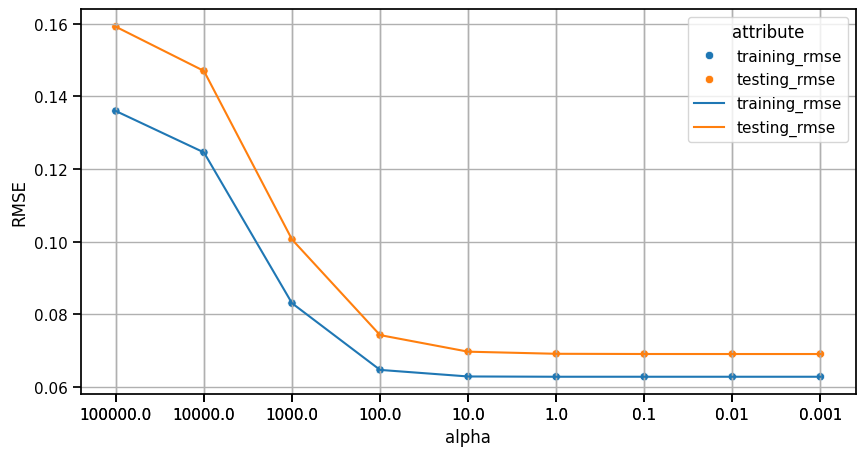

In [18]:
plt.figure(figsize=(10,5))
sns.set_context('notebook',font_scale=1)
ax = sns.scatterplot(data=df_melted,x='RANK',y='value',hue='attribute')
sns.lineplot(data=df_melted,x='RANK',y='value',hue='attribute')
ax.set_xticks(df_melted['RANK'],df_melted['alpha'])
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.grid()

In [19]:
print('Alpha terbaik:', best_alpha)
print('Nilai RMSE:', score)

Alpha terbaik: 0.001
Nilai RMSE: 0.06909962415313735


In [20]:
pd.DataFrame(
    {
        'alpha': alpha,
        'train RMSE': training_rmse,
        'test RMSE': testing_rmse
    }
)

,alpha,train RMSE,test RMSE
0,100000.000,0.135999,0.159200
1,10000.000,0.124604,0.147037
2,1000.000,0.083092,0.100641
3,100.000,0.064727,0.074309
4,10.000,0.062919,0.069744
5,1.000,0.062843,0.069164
6,0.100,0.062842,0.069106
7,0.010,0.062842,0.069100
8,0.001,0.062842,0.069100


## **Comparing RMSE**

In [21]:
# Fitting
ridgereg = Ridge(alpha = best_alpha)
ridgereg.fit(X_train, y_train)

Ridge(alpha=0.001)

In [22]:
# Predict y_train and y_test
y_reg_train = ridgereg.predict(X_train)
y_reg_test = ridgereg.predict(X_test)

In [23]:
# Coeff pada model ridge
coef_ridgereg = pd.DataFrame({
    'feature_name': list(X),
    'feature_coef': ridgereg.coef_
})

In [24]:
coef_ridgereg

,feature_name,feature_coef
0,GRE Score,0.026780
1,TOEFL Score,0.016825
2,University Rating,0.009117
3,SOP,0.000226
4,LOR,0.014807
5,CGPA,0.066511


In [25]:
print('RMSE train:', rmse(y_train, y_reg_train))
print('RMSE test:', rmse(y_test, y_reg_test))

RMSE train: 0.06284241642438144
RMSE test: 0.06909962415313735


In [26]:
# print('RMSE train:', rmse(y_train, y_reg_train))
# print('RMSE test:', rmse(y_test, y_reg_test))

## **Interpretasi**

- Semakin besar nilai alpha, maka semakin besar pula penalti yang diberikan pada setiap variabel.
- Pada Ridge, semakin besar alpha, maka cofficient regresi akan semakin kecil, tapi tidak sampai menjadi 0
- Jika nilai alpha terlalu tinggi, model memiliki kecenderungan underfitting, di mana nilai MSE pada train dan test set masih besar (Alpha 100000 sampai 10).
<br><br>
- Nilai alpha terbaik = 1 dengan RMSE 0.069164.


## **Lasso Regression**

In [27]:
df

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65
...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1,0.82
396,397,325,107,3,3.0,3.5,9.11,1,0.84
397,398,330,116,4,5.0,4.5,9.45,1,0.91
398,399,312,103,3,3.5,4.0,8.78,0,0.67


In [28]:
# Lasso

alpha = [100000, 10000, 1000, 100, 10, 1, 0.1, 0.01, 0.001, 0.0001, 0.00001]
# testing_rmse = []
# training_rmse = []
testing_mse = []
training_mse = []
score = 0

# for i in range(len(alpha)):
#     lasso = Lasso(alpha=alpha[i])
#     lasso.fit(X_train, y_train)
    
#     y_predict_train = lasso.predict(X_train)
#     training_rmse.append(mean_squared_error(y_train, y_predict_train))
    
#     y_predict_test = lasso.predict(X_test)
#     rmse_score = mean_squared_error(y_test, y_predict_test)
#     testing_rmse.append(rmse_score)
    
#     if i==0:
#         score = rmse_score
#         best_alpha = alpha[i]
        
#     if score > rmse_score:
#         score = rmse_score
#         best_alpha = alpha[i]

for i in range(len(alpha)):
    lasso = Lasso(alpha=alpha[i])
    lasso.fit(X_train, y_train)
    
    y_predict_train = lasso.predict(X_train)
    training_mse.append(mean_squared_error(y_train, y_predict_train))
    
    y_predict_test = lasso.predict(X_test)
    mse_score = mean_squared_error(y_test, y_predict_test)
    testing_mse.append(mse_score)
    
    if i==0:
        score = mse_score
        best_alpha = alpha[i]
        
    if score > mse_score:
        score = mse_score
        best_alpha = alpha[i]

In [29]:
# df_c = pd.DataFrame(
#     {'alpha':alpha,
#      'training_rmse':training_rmse,
#      'testing_rmse':testing_rmse}
# )
# df_melted = pd.melt(df_c,id_vars=['alpha'],value_vars=['training_rmse','testing_rmse'],value_name='value',var_name='attribute')
# df_melted['RANK'] = df_melted.groupby('attribute')['alpha'].rank(method='first',ascending=False)
# df_melted

df_c = pd.DataFrame(
    {'alpha':alpha,
     'training_mse':training_mse,
     'testing_mse':testing_mse}
)
df_melted = pd.melt(df_c,id_vars=['alpha'],value_vars=['training_mse','testing_mse'],value_name='value',var_name='attribute')
df_melted['RANK'] = df_melted.groupby('attribute')['alpha'].rank(method='first',ascending=False)
df_melted

,alpha,attribute,value,RANK
0,100000.00000,training_mse,0.018898,1.0
1,10000.00000,training_mse,0.018898,2.0
2,1000.00000,training_mse,0.018898,3.0
3,100.00000,training_mse,0.018898,4.0
4,10.00000,training_mse,0.018898,5.0
5,1.00000,training_mse,0.018898,6.0
6,0.10000,training_mse,0.014629,7.0
7,0.01000,training_mse,0.004087,8.0
8,0.00100,training_mse,0.003951,9.0
9,0.00010,training_mse,0.003949,10.0


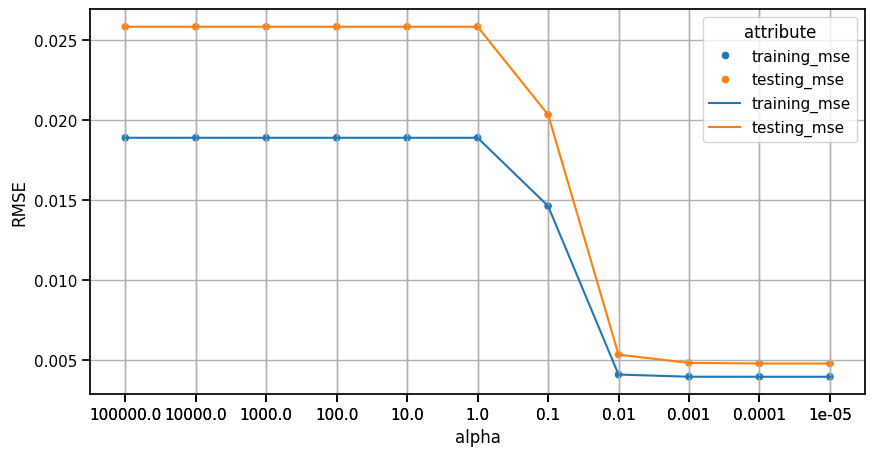

In [30]:
plt.figure(figsize=(10,5))
sns.set_context('notebook',font_scale=1)
ax = sns.scatterplot(data=df_melted,x='RANK',y='value',hue='attribute')
sns.lineplot(data=df_melted,x='RANK',y='value',hue='attribute')
ax.set_xticks(df_melted['RANK'],df_melted['alpha'])
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.grid()

In [31]:
print('Alpha terbaik:', best_alpha)
# print('Nilai RMSE:', score)
print('Nilai MSE:', score)

Alpha terbaik: 1e-05
Nilai MSE: 0.004775150839906699


In [32]:
# pd.DataFrame(
#     {
#         'alpha': alpha,
#         'train RMSE': training_rmse,
#         'test RMSE': testing_rmse
#     }
# )

pd.DataFrame(
    {
        'alpha': alpha,
        'train MSE': training_mse,
        'test MSE': testing_mse
    }
)

,alpha,train MSE,test MSE
0,100000.00000,0.018898,0.025845
1,10000.00000,0.018898,0.025845
2,1000.00000,0.018898,0.025845
3,100.00000,0.018898,0.025845
4,10.00000,0.018898,0.025845
5,1.00000,0.018898,0.025845
6,0.10000,0.014629,0.020345
7,0.01000,0.004087,0.005333
8,0.00100,0.003951,0.004815
9,0.00010,0.003949,0.004779


## **Comparing MSE**

In [33]:
# Fitting
lassoreg = Lasso(alpha = best_alpha)
lassoreg.fit(X_train, y_train)

Lasso(alpha=1e-05)

In [34]:
# Predict
y_reg_train = lassoreg.predict(X_train)
y_reg_test = lassoreg.predict(X_test)

In [35]:
coef_lassoreg = pd.DataFrame({
    'feature_names': list(X),
    'feature_coef': lassoreg.coef_
})

In [36]:
coef_lassoreg

,feature_names,feature_coef
0,GRE Score,0.026777
1,TOEFL Score,0.016821
2,University Rating,0.009114
3,SOP,0.000224
4,LOR,0.014802
5,CGPA,0.066514


In [37]:
print('MSE train:', mean_squared_error(y_train, y_reg_train))
print('MSE test:', mean_squared_error(y_test, y_reg_test))

MSE train: 0.00394916944276038
MSE test: 0.004775150839906699


In [38]:
# print('RMSE train:', rmse(y_train, y_reg_train))
# print('RMSE test:', rmse(y_test, y_reg_test))

## **Interpretasi**

- Pada Lasso, semakin besar nilai alpha, maka coefficient regresi semakin kecil, bahkan bisa sampai 0 
- Jika nilai alpha terlalu tinggi, model memiliki kecenderungan underfitting karena nilai MSE dari train dan test set masih tinggi (alpha 100000 sampai 0.01).
- Didapat nilai alpha terbaik = 0.001 dan selisih nilai RMSE antar kedua set berbeda tidak terlalu jauh.

## **Experiment**

In [39]:
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)

Lasso(alpha=0.1)

In [40]:
pd.DataFrame({
    'feature names': list(X),
    'coef': lasso.coef_
})

,feature names,coef
0,GRE Score,0.000000
1,TOEFL Score,0.000000
2,University Rating,0.000000
3,SOP,0.000000
4,LOR,0.000000
5,CGPA,0.019452


- Lasso bisa juga digunakan sebagai feature selection karena bisa membuat nilai coeficient dari variable menjadi 0.
- Semakin besar nilai alpha, maka penalti yang diberikan pun akan semakin besar, sehingga membuat nilai coeficient dapat menjadi 0. Dalam contoh di atas, jika alpha diset = 0.1, yang terjadi adalah nilai coef untuk hampir semua variabel menjadi 0, kecuali CGPA.

## **Conclusion**

1. Linear Regression
    - RMSE: 0.069099
<br><br>
2. Ridge regression
   - Alpha terbaik = 1
   - RMSE test = 0.069163
<br><br>
3. Lasso regression
   - Alpha terbaik = 0.001
   - RMSE test = 0.06939


Data boston ini performa modelnya sudah bagus walaupun hanya menggunakan Linear Regression (tanpa ada penalty).


